# Repaso del examen: IFC33W-FEST — el festival de música

El instituto organiza su festival de música: dos escenarios, puestos de comida y bebida y una zona de asientos numerada. El equipo de organización se ha escrito pequeños programas que cuentan las ventas de los puestos, controlan el stock de la barra, reparten las pulseras, organizan las bandas y cifran el cartel.

Este cuaderno repasa los 10 ejercicios del examen del 20 de noviembre: tres preguntas de test, cuatro seguimientos de código y tres funciones. Cada ejercicio es independiente: las variables empiezan de nuevo en cada uno.

## Cómo se ha corregido

- El examen suma **30 puntos**: parte A, 6; parte B, 12; parte C, 12.
- En la parte A hay **2 puntos por acierto**, con una sola opción correcta por pregunta.
- En cada seguimiento de la parte B, 2 puntos corresponden a la tabla de variables y 1 punto a la salida exacta.
- En la parte C se puntúa por criterios y se aceptan algoritmos equivalentes que cumplan el contrato con lo visto en clase.

El solucionario deja pendientes de fijar la penalización por fallo en el test, los mínimos por parte y las condiciones de aprobado.

## Caja de herramientas visual

Ejecutad esta celda una sola vez. Prepara la pizarra, las listas, los avances y las tablas que usaremos durante el repaso.

In [1]:
#@title Caja de herramientas visual
import doctest
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

FONDO_PIZARRA = "#164638"
TIZA = "#f3f0df"
TIZA_AMARILLA = "#ffe36e"
TIZA_AZUL = "#a9d7ef"

def dibujar_pizarra(titulo, lineas, ancho=10, alto=3.3):
    """Dibuja una idea con texto y flechas sobre fondo de pizarra."""
    fig, ax = plt.subplots(figsize=(ancho, alto), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.045, 0.91, titulo, color=TIZA_AMARILLA, fontsize=17,
            fontweight="bold", family="DejaVu Sans Mono", va="top")
    cantidad = max(1, len(lineas))
    paso = 0.77 / cantidad
    tamano = 14 if cantidad <= 4 else 12
    for numero, linea in enumerate(lineas):
        if isinstance(linea, tuple):
            texto, color = linea
        else:
            texto, color = linea, TIZA
        ax.text(0.055, 0.78 - numero * paso, texto, color=color,
                fontsize=tamano, family="DejaVu Sans Mono", va="top",
                wrap=True)
    fig.tight_layout(pad=0.5)
    display(fig)
    plt.close(fig)

def dibujar_estante(estante, marcar=(), titulo=""):
    """Dibuja las casillas de un estante con los índices debajo."""
    fig, ax = plt.subplots(figsize=(max(5, 1.15 * len(estante)), 2.6), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.text(-0.1, 1.45, titulo, color=TIZA_AMARILLA,
            fontsize=15, fontweight="bold", family="DejaVu Sans Mono",
            va="center")
    for i, letra in enumerate(estante):
        resaltada = i in marcar
        ax.add_patch(Rectangle((i, 0), 1, 1,
                               facecolor="#205b49",
                               edgecolor=TIZA_AMARILLA if resaltada else TIZA,
                               linewidth=2.5 if resaltada else 1.5))
        ax.text(i + 0.5, 0.56, letra, ha="center", va="center",
                fontsize=20, color=TIZA_AMARILLA if resaltada else TIZA,
                family="DejaVu Sans Mono", fontweight="bold")
        ax.text(i + 0.5, -0.2, str(i), ha="center", va="center",
                fontsize=12, color=TIZA)
    ax.set_xlim(-0.15, max(1, len(estante)) + 0.15)
    ax.set_ylim(-0.55, 1.9)
    ax.axis("off")
    display(fig)
    plt.close(fig)

def dibujar_lista(elementos, marcar=(), titulo=""):
    """Dibuja una casilla por elemento de lista, con los índices debajo."""
    fig, ax = plt.subplots(figsize=(max(5, 1.15 * len(elementos)), 2.6), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.text(-0.1, 1.45, titulo, color=TIZA_AMARILLA,
            fontsize=15, fontweight="bold", family="DejaVu Sans Mono",
            va="center")
    for i, elemento in enumerate(elementos):
        resaltada = i in marcar
        ax.add_patch(Rectangle((i, 0), 1, 1,
                               facecolor="#205b49",
                               edgecolor=TIZA_AMARILLA if resaltada else TIZA,
                               linewidth=2.5 if resaltada else 1.5))
        ax.text(i + 0.5, 0.56, str(elemento), ha="center", va="center",
                fontsize=17, color=TIZA_AMARILLA if resaltada else TIZA,
                family="DejaVu Sans Mono", fontweight="bold")
        ax.text(i + 0.5, -0.2, str(i), ha="center", va="center",
                fontsize=12, color=TIZA)
    ax.set_xlim(-0.15, max(1, len(elementos)) + 0.15)
    ax.set_ylim(-0.55, 1.9)
    ax.axis("off")
    display(fig)
    plt.close(fig)

def dibujar_listas_doble(antes, despues, titulo, nota=""):
    """Compara la lista original y la lista nueva en la misma pizarra."""
    fig, ax = plt.subplots(figsize=(10, 3.1), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.03, 0.94, titulo, transform=ax.transAxes, color=TIZA_AMARILLA,
            fontsize=16, fontweight="bold", family="DejaVu Sans Mono", va="top")
    ancho = max(len(antes), len(despues))
    for fila, (etiqueta, elementos) in enumerate(
            (("antes", antes), ("después", despues))):
        y = 0.60 - fila * 0.40
        ax.text(0.04, y + 0.10, etiqueta, transform=ax.transAxes,
                color=TIZA_AZUL, fontsize=13, family="DejaVu Sans Mono")
        for i, elemento in enumerate(elementos):
            x = 0.21 + 0.73 * i / max(1, ancho)
            w = 0.68 / max(1, ancho)
            ax.add_patch(Rectangle((x, y - 0.05), w, 0.23,
                                   transform=ax.transAxes,
                                   facecolor="#205b49",
                                   edgecolor=TIZA, linewidth=1.2))
            ax.text(x + w / 2, y + 0.065, str(elemento),
                    transform=ax.transAxes, ha="center", va="center",
                    fontsize=15, color=TIZA_AMARILLA,
                    family="DejaVu Sans Mono", fontweight="bold")
    if nota:
        ax.text(0.5, 0.02, nota, transform=ax.transAxes, ha="center",
                color=TIZA_AMARILLA, fontsize=12,
                family="DejaVu Sans Mono")
    display(fig)
    plt.close(fig)

def dibujar_avances(posiciones, marca, titulo, nota=""):
    """Dibuja los saltos de un contador sobre una recta, con su marca."""
    fig, ax = plt.subplots(figsize=(9, 3.0), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ultima = max(max(posiciones), marca)
    ax.set_xlim(-0.9, ultima + 0.9)
    ax.set_ylim(-1.05, 2.2)
    ax.axis("off")
    ax.text(0.5, 0.98, titulo, transform=ax.transAxes, ha="center", va="top",
            color=TIZA_AMARILLA, fontsize=15, fontweight="bold",
            family="DejaVu Sans Mono")
    ax.plot([-0.6, ultima + 0.6], [0, 0], color=TIZA, linewidth=2)
    for casilla in range(ultima + 1):
        visitada = casilla in posiciones
        ax.add_patch(Rectangle((casilla - 0.34, -0.28), 0.68, 0.56,
                               facecolor="#205b49",
                               edgecolor=TIZA_AMARILLA if visitada else TIZA,
                               linewidth=2 if visitada else 1))
        ax.text(casilla, -0.58, str(casilla), ha="center", va="top",
                color=TIZA, fontsize=11, family="DejaVu Sans Mono")
    for paso, (origen, destino) in enumerate(
            zip(posiciones, posiciones[1:]), 1):
        altura = 0.56 + 0.24 * (paso - 1)
        ax.annotate("", xy=(destino, altura), xytext=(origen, altura),
                    arrowprops={"arrowstyle": "-|>", "color": TIZA_AMARILLA,
                                "linewidth": 2})
        ax.text((origen + destino) / 2, altura + 0.10,
                f"+{destino - origen}", ha="center", color=TIZA, fontsize=10,
                family="DejaVu Sans Mono")
    ax.plot([marca, marca], [-0.34, 1.50], color=TIZA_AZUL, linewidth=2,
            linestyle="--")
    ax.text(marca, 1.58, f"marca {marca}", ha="center", color=TIZA_AZUL,
            fontsize=11, family="DejaVu Sans Mono")
    ax.plot(posiciones[-1], 0, marker="s", markersize=11,
            color=TIZA_AMARILLA, markeredgecolor=TIZA)
    if nota:
        ax.text(0.5, 0.02, nota, transform=ax.transAxes, ha="center",
                color=TIZA_AMARILLA, fontsize=12,
                family="DejaVu Sans Mono")
    display(fig)
    plt.close(fig)

def tabla_html(filas, columnas):
    """Construye una tabla estática para seguir una vuelta cada vez."""
    estilo = "border:1px solid #b8cbbf;padding:6px 14px;text-align:center;font-size:16px"
    cabecera = "".join(
        f'<th style="{estilo};background:#205b49;color:#fff">{c}</th>'
        for c in columnas
    )
    filas_html = "".join(
        "<tr>" + "".join(
            f'<td style="{estilo};color:#18382e">{fila[c]}</td>'
            for c in columnas
        ) + "</tr>"
        for fila in filas
    )
    return HTML(
        '<table style="border-collapse:collapse">'
        f"<tr>{cabecera}</tr>{filas_html}</table>"
    )

def traza_pasos(filas, columnas):
    """Presenta los datos de cada vuelta en orden."""
    display(tabla_html(filas, columnas))

def dibujar_tabla_pizarra(titulo, columnas, filas, pesos=None):
    """Dibuja una tabla de seguimiento legible en la pizarra."""
    fig, ax = plt.subplots(figsize=(10, max(2.8, 0.48 * (len(filas) + 2))), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.5, 0.96, titulo, transform=ax.transAxes, ha="center", va="top",
            color=TIZA_AMARILLA, fontsize=15, fontweight="bold",
            family="DejaVu Sans Mono")
    izquierda, derecha = 0.05, 0.95
    arriba, abajo = 0.82, 0.08
    if pesos is None:
        pesos = [1] * len(columnas)
    total = sum(pesos)
    anchos = [p / total * (derecha - izquierda) for p in pesos]
    bordes = [izquierda + sum(anchos[:c]) for c in range(len(columnas) + 1)]
    alto = (arriba - abajo) / (len(filas) + 1)
    for r in range(len(filas) + 2):
        y = arriba - r * alto
        ax.plot([izquierda, derecha], [y, y], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    for c in range(len(columnas) + 1):
        x = bordes[c]
        ax.plot([x, x], [abajo, arriba], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    tabla = [columnas] + filas
    for r, fila in enumerate(tabla):
        for c, valor in enumerate(fila):
            x = bordes[c] + anchos[c] / 2
            y = arriba - (r + 0.5) * alto
            ax.text(x, y, str(valor), transform=ax.transAxes, ha="center",
                    va="center", color=TIZA_AMARILLA if r == 0 else TIZA,
                    fontsize=12, family="DejaVu Sans Mono")
    display(fig)
    plt.close(fig)

print("Caja lista: pizarra, listas, avances y tablas.")


Caja lista: pizarra, listas, avances y tablas.


## A1 · Las etiquetas de los asientos (2 puntos)

### Enunciado exacto

La zona de asientos del festival tiene las filas «A» y «B», cada una con tres asientos numerados. Este programa cuenta cuántas etiquetas de asiento se generan. ¿Qué imprime?

```python
filas = ["A", "B"]
etiquetas = 0
for f in filas:
    for n in [1, 2, 3]:
        etiquetas = etiquetas + 1
print(etiquetas)
```

a) 6     b) 5
c) 3     d) 2

### Pizarra

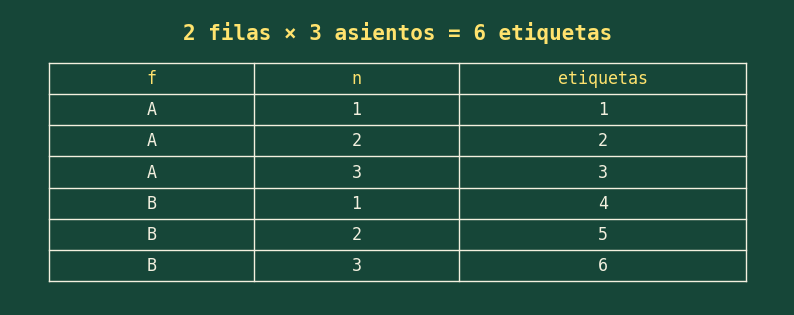

In [2]:
dibujar_tabla_pizarra(
    "2 filas × 3 asientos = 6 etiquetas",
    ["f", "n", "etiquetas"],
    [["A", "1", "1"], ["A", "2", "2"], ["A", "3", "3"],
     ["B", "1", "4"], ["B", "2", "5"], ["B", "3", "6"]],
    pesos=[1, 1, 1.4],
)

In [3]:
filas = ["A", "B"]
etiquetas = 0
for f in filas:
    for n in [1, 2, 3]:
        etiquetas = etiquetas + 1
print(etiquetas)

6


**Paso a paso.** El bucle exterior da 2 vueltas y el interior 3 por cada una: `etiquetas` suma 1 seis veces en total (2 × 3). Se imprime `6`. La respuesta es **a) 6**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=filas%20%3D%20%5B%22A%22%2C%20%22B%22%5D%0Aetiquetas%20%3D%200%0Afor%20f%20in%20filas%3A%0A%20%20%20%20for%20n%20in%20%5B1%2C%202%2C%203%5D%3A%0A%20%20%20%20%20%20%20%20etiquetas%20%3D%20etiquetas%20%2B%201%0Aprint%28etiquetas%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta correcta: a) 6 — 2 p por acierto. | 2 |

#### Errores frecuentes

- Responder 5: suma 2 + 3 en vez de multiplicar 2 × 3 (opción b).
- Responder 3: cuenta solo las vueltas del bucle interior una vez (opción c).
- Responder 2: cuenta solo las vueltas del bucle exterior (opción d).

## A2 · El stock de la barra (2 puntos)

### Enunciado exacto

En la barra del festival, el stock de cada producto se lleva en un diccionario. ¿Qué imprime este código?

```python
stock = {"agua": 5, "pizza": 2}
stock["agua"] = stock["agua"] - 2
print(stock.get("zumo", 0), stock["agua"])
```

a) None 3       b) 0 5
c) 0 3    d) Error (KeyError)

### Pizarra

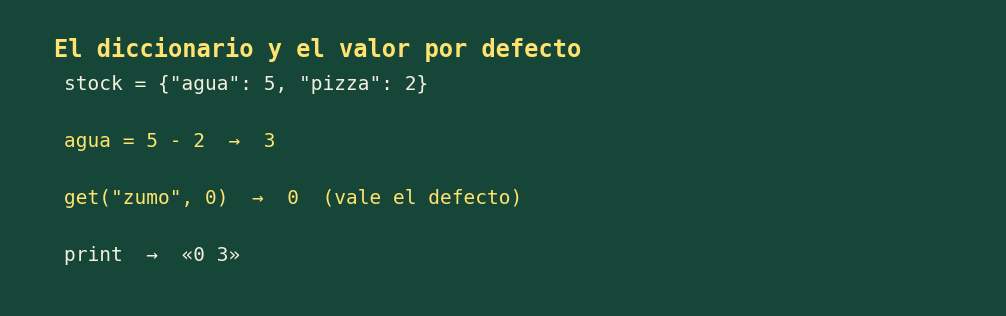

In [4]:
dibujar_pizarra(
    'El diccionario y el valor por defecto',
    [('stock = {"agua": 5, "pizza": 2}', TIZA),
    ('agua = 5 - 2  →  3', TIZA_AMARILLA),
    ('get("zumo", 0)  →  0  (vale el defecto)', TIZA_AMARILLA),
    ('print  →  «0 3»', TIZA)],
    ancho=10, alto=3.1,
)

In [5]:
stock = {"agua": 5, "pizza": 2}
stock["agua"] = stock["agua"] - 2
print(stock.get("zumo", 0), stock["agua"])

0 3


**Paso a paso.** `stock["agua"]` pasa de 5 a 3 con la operación `5 - 2`. `stock.get("zumo", 0)` no encuentra la clave y devuelve el valor por defecto `0` sin error. Se imprime `0 3`. La respuesta es **c) 0 3**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=stock%20%3D%20%7B%22agua%22%3A%205%2C%20%22pizza%22%3A%202%7D%0Astock%5B%22agua%22%5D%20%3D%20stock%5B%22agua%22%5D%20-%202%0Aprint%28stock.get%28%22zumo%22%2C%200%29%2C%20stock%5B%22agua%22%5D%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta correcta: c) 0 3 — 2 p por acierto. | 2 |

#### Errores frecuentes

- Responder `None 3`: `get` devuelve el valor por defecto cuando se pasa uno, no `None` (opción a).
- Responder `0 5`: ignora que `agua` se actualiza a 3 antes del `print` (opción b).
- Responder Error (KeyError): confunde `stock.get("zumo", 0)` con `stock["zumo"]` (opción d).

## A3 · Las ventas del puesto de camisetas (2 puntos)

### Enunciado exacto

En el puesto de camisetas del festival se anota el precio de cada venta en euros. El encargado suma solo las ventas de más de 4 euros. ¿Qué imprime este código?

```python
ventas = [3, 7, 2, 8, 5]
total = 0
for v in ventas:
    if v > 4:
        total = total + v
print(total)
```

a) 25    b) 20
c) 3    d) 15

### Pizarra

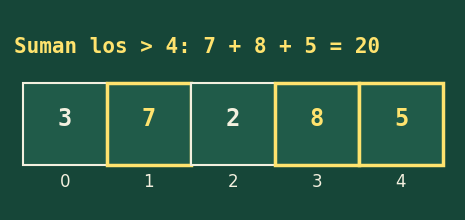

In [6]:
dibujar_lista([3, 7, 2, 8, 5], marcar=[1, 3, 4], titulo="Suman los > 4: 7 + 8 + 5 = 20")

In [7]:
ventas = [3, 7, 2, 8, 5]
total = 0
for v in ventas:
    if v > 4:
        total = total + v
print(total)

20


**Paso a paso.** El `for` recorre la lista y solo suma los valores estrictamente mayores que 4: 7 + 8 + 5 = 20. El 3 y el 2 no entran. Se imprime `20`. La respuesta es **b) 20**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=ventas%20%3D%20%5B3%2C%207%2C%202%2C%208%2C%205%5D%0Atotal%20%3D%200%0Afor%20v%20in%20ventas%3A%0A%20%20%20%20if%20v%20%3E%204%3A%0A%20%20%20%20%20%20%20%20total%20%3D%20total%20%2B%20v%0Aprint%28total%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta correcta: b) 20 — 2 p por acierto. | 2 |

#### Errores frecuentes

- Responder 25: suma todas las ventas e ignora el `if` (opción a).
- Responder 3: cuenta las ventas que cumplen la condición en vez de sumarlas (opción c).
- Responder 15: aplica `> 5` en vez de `> 4`, un error de frontera (opción d).

## B1 · Las revistas del almacén (3 puntos)

### Enunciado exacto

El equipo del festival descarga las revistas-programa que llegan al almacén en paquetes de cuatro: revistas cuenta las unidades recibidas y paquetes los envases abiertos. Se detiene en cuanto recibe 10 o más. Completa la tabla y escribe la salida exacta.

```python
revistas = 0
paquetes = 0
while True:
    revistas = revistas + 4
    paquetes = paquetes + 1
    if revistas >= 10:
        break
print("revistas:", revistas)
print("paquetes:", paquetes)
```

Columnas de la tabla: vuelta | revistas | paquetes.

### Pizarra

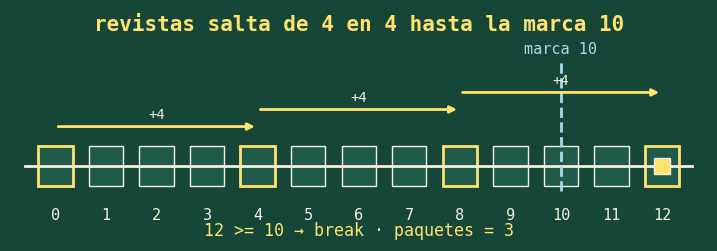

In [8]:
dibujar_avances([0, 4, 8, 12], 10, "revistas salta de 4 en 4 hasta la marca 10", nota="12 >= 10 → break · paquetes = 3")

In [9]:
revistas = 0
paquetes = 0
while True:
    revistas = revistas + 4
    paquetes = paquetes + 1
    if revistas >= 10:
        break
print("revistas:", revistas)
print("paquetes:", paquetes)

revistas: 12
paquetes: 3


In [10]:
filas_b1 = [{'vuelta': '1', 'revistas': '4', 'paquetes': '1'}, {'vuelta': '2', 'revistas': '8', 'paquetes': '2'}, {'vuelta': '3', 'revistas': '12', 'paquetes': '3 (break)'}]
traza_pasos(filas_b1, ['vuelta', 'revistas', 'paquetes'])

vuelta,revistas,paquetes
1,4,1
2,8,2
3,12,3 (break)


**Paso a paso.** En cada vuelta `revistas` sube 4 y `paquetes` suma 1. La tercera vuelta deja `revistas` en 12; como 12 ya alcanza el 10, el `break` detiene el bucle y esa vuelta también se anota. Los dos `print` muestran `revistas: 12` y `paquetes: 3`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=revistas%20%3D%200%0Apaquetes%20%3D%200%0Awhile%20True%3A%0A%20%20%20%20revistas%20%3D%20revistas%20%2B%204%0A%20%20%20%20paquetes%20%3D%20paquetes%20%2B%201%0A%20%20%20%20if%20revistas%20%3E%3D%2010%3A%0A%20%20%20%20%20%20%20%20break%0Aprint%28%22revistas%3A%22%2C%20revistas%29%0Aprint%28%22paquetes%3A%22%2C%20paquetes%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla de variables: valores/registros correctos al final de cada vuelta, incluida la vuelta del break (columnas ya impresas; no se puntúa dibujarlas) | 2,0 |
| Salida exacta: contenido correcto (0,5) · orden y formato exactos — corchetes, comillas, orden de líneas (0,5) | 1,0 |

#### Errores frecuentes

- No anotar la vuelta en la que salta el `break`: la rúbrica la pide también.
- Añadir filas después del `break`, cuando el bucle ya ha terminado.
- Confundir las unidades (`revistas`) con los envases (`paquetes`).

## B2 · El primer retraso (3 puntos)

### Enunciado exacto

Los técnicos del festival anotan los minutos de retraso de cada grupo y quieren la posición del primero que supera los 10 minutos. Completa la tabla y escribe la salida exacta.

```python
datos = [3, 8, 6, 15, 2]
posicion = 0
encontrado = -1
for d in datos:
    if d > 10:
        encontrado = posicion
        break
    posicion = posicion + 1
print("posicion:", encontrado)
```

Columnas de la tabla: vuelta | d | posicion | encontrado.

### Pizarra

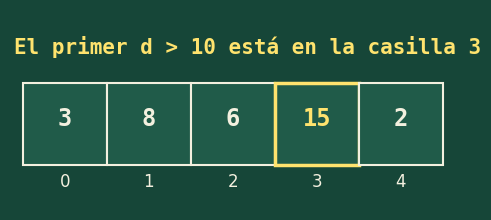

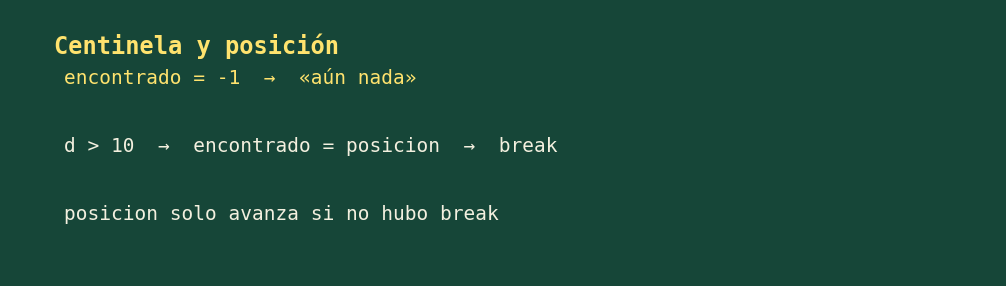

In [11]:
dibujar_lista([3, 8, 6, 15, 2], marcar=[3], titulo="El primer d > 10 está en la casilla 3")
dibujar_pizarra(
    'Centinela y posición',
    [('encontrado = -1  →  «aún nada»', TIZA_AMARILLA),
    ('d > 10  →  encontrado = posicion  →  break', TIZA),
    ('posicion solo avanza si no hubo break', TIZA)],
    ancho=10, alto=2.8,
)

In [12]:
datos = [3, 8, 6, 15, 2]
posicion = 0
encontrado = -1
for d in datos:
    if d > 10:
        encontrado = posicion
        break
    posicion = posicion + 1
print("posicion:", encontrado)

posicion: 3


In [13]:
filas_b2 = [{'vuelta': '1', 'd': '3', 'posicion': '1', 'encontrado': '-1'}, {'vuelta': '2', 'd': '8', 'posicion': '2', 'encontrado': '-1'}, {'vuelta': '3', 'd': '6', 'posicion': '3', 'encontrado': '-1'}, {'vuelta': '4', 'd': '15', 'posicion': '3', 'encontrado': '3 (break)'}]
traza_pasos(filas_b2, ['vuelta', 'd', 'posicion', 'encontrado'])

vuelta,d,posicion,encontrado
1,3,1,-1
2,8,2,-1
3,6,3,-1
4,15,3,3 (break)


**Paso a paso.** `encontrado` nace en -1 como señal de «aún nada». El bucle mira cada retraso: en la cuarta vuelta `d` vale 15, mayor que 10, así que `encontrado` guarda `posicion`, que vale 3, y el `break` corta. Se imprime `posicion: 3`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=datos%20%3D%20%5B3%2C%208%2C%206%2C%2015%2C%202%5D%0Aposicion%20%3D%200%0Aencontrado%20%3D%20-1%0Afor%20d%20in%20datos%3A%0A%20%20%20%20if%20d%20%3E%2010%3A%0A%20%20%20%20%20%20%20%20encontrado%20%3D%20posicion%0A%20%20%20%20%20%20%20%20break%0A%20%20%20%20posicion%20%3D%20posicion%20%2B%201%0Aprint%28%22posicion%3A%22%2C%20encontrado%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla de variables: valores/registros correctos al final de cada vuelta, incluida la vuelta del break (columnas ya impresas; no se puntúa dibujarlas) | 2,0 |
| Salida exacta: contenido correcto (0,5) · orden y formato exactos — corchetes, comillas, orden de líneas (0,5) | 1,0 |

#### Errores frecuentes

- Arrastrar el centinela: `encontrado` sigue en -1 hasta la vuelta del `break`.
- Contar la posición desde 1: `posicion` empieza en 0 y solo avanza cuando no hubo `break`.
- No anotar la vuelta del `break`, que la rúbrica pide también.

## B3 · Dígitos y letras de una referencia (3 puntos)

### Enunciado exacto

El equipo del festival copia la referencia «m4r7a» de una caja de material del escenario y separa los dígitos, que apunta para el inventario, de las letras. Completa la tabla y escribe la salida exacta.

```python
ref = "m4r7a"
digitos = []
letras = 0
for c in ref:
    if c in "0123456789":
        digitos.append(c)
    else:
        letras = letras + 1
print(digitos)
print("letras:", letras)
```

Columnas de la tabla: vuelta | c | digitos | letras.

### Pizarra

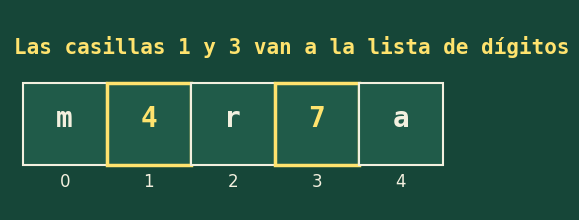

In [14]:
dibujar_estante("m4r7a", marcar=[1, 3], titulo="Las casillas 1 y 3 van a la lista de dígitos")

In [15]:
ref = "m4r7a"
digitos = []
letras = 0
for c in ref:
    if c in "0123456789":
        digitos.append(c)
    else:
        letras = letras + 1
print(digitos)
print("letras:", letras)

['4', '7']
letras: 3


In [16]:
filas_b3 = [{'vuelta': '1', 'c': 'm', 'digitos': '[]', 'letras': '1'}, {'vuelta': '2', 'c': '4', 'digitos': "['4']", 'letras': '1'}, {'vuelta': '3', 'c': 'r', 'digitos': "['4']", 'letras': '2'}, {'vuelta': '4', 'c': '7', 'digitos': "['4', '7']", 'letras': '2'}, {'vuelta': '5', 'c': 'a', 'digitos': "['4', '7']", 'letras': '3'}]
traza_pasos(filas_b3, ['vuelta', 'c', 'digitos', 'letras'])

vuelta,c,digitos,letras
1,m,[],1
2,4,['4'],1
3,r,['4'],2
4,7,"['4', '7']",2
5,a,"['4', '7']",3


**Paso a paso.** El `for` recorre la referencia carácter a carácter. Las cifras `4` y `7` entran en la lista `digitos`; las letras `m`, `r` y `a` solo suben el contador `letras`. Se imprime `['4', '7']` y `letras: 3`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=ref%20%3D%20%22m4r7a%22%0Adigitos%20%3D%20%5B%5D%0Aletras%20%3D%200%0Afor%20c%20in%20ref%3A%0A%20%20%20%20if%20c%20in%20%220123456789%22%3A%0A%20%20%20%20%20%20%20%20digitos.append%28c%29%0A%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20letras%20%3D%20letras%20%2B%201%0Aprint%28digitos%29%0Aprint%28%22letras%3A%22%2C%20letras%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla de variables: valores/registros correctos al final de cada vuelta, incluida la vuelta del break (columnas ya impresas; no se puntúa dibujarlas) | 2,0 |
| Salida exacta: contenido correcto (0,5) · orden y formato exactos — corchetes, comillas, orden de líneas (0,5) | 1,0 |

#### Errores frecuentes

- Guardar en `digitos` las letras en vez de las cifras: solo entran los caracteres de `"0123456789"`.
- Subir `letras` en las vueltas de los dígitos: solo sube en el `else`.
- Escribir la lista sin comillas o con otro formato: la salida exacta puntúa corchetes y comillas.

## B4 · El pedido de la barra (3 puntos)

### Enunciado exacto

En la barra del festival se apunta la comanda de un cliente: se suma el total de lo que está en la carta y se cuenta aparte lo que no está. Completa la tabla y escribe la salida exacta.

```python
menu = {"cafe": 1, "te": 2, "donut": 2}
pedido = ["cafe", "te", "zumo", "te", "cafe"]
total = 0
desconocidos = 0
for p in pedido:
    precio = menu.get(p, -1)
    if precio >= 0:
        total = total + precio
    else:
        desconocidos = desconocidos + 1
print("total:", total)
print("desconocidos:", desconocidos)
```

Columnas de la tabla: vuelta | p | precio | total | desconocidos.

### Pizarra

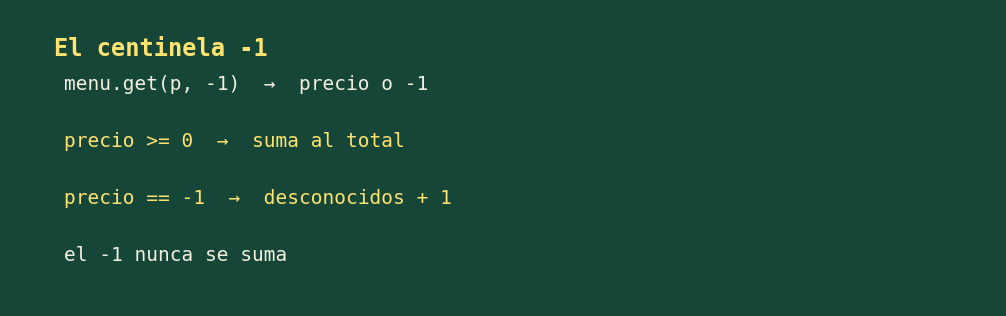

In [17]:
dibujar_pizarra(
    'El centinela -1',
    [('menu.get(p, -1)  →  precio o -1', TIZA),
    ('precio >= 0  →  suma al total', TIZA_AMARILLA),
    ('precio == -1  →  desconocidos + 1', TIZA_AMARILLA),
    ('el -1 nunca se suma', TIZA)],
    ancho=10, alto=3.1,
)

In [18]:
menu = {"cafe": 1, "te": 2, "donut": 2}
pedido = ["cafe", "te", "zumo", "te", "cafe"]
total = 0
desconocidos = 0
for p in pedido:
    precio = menu.get(p, -1)
    if precio >= 0:
        total = total + precio
    else:
        desconocidos = desconocidos + 1
print("total:", total)
print("desconocidos:", desconocidos)

total: 6
desconocidos: 1


In [19]:
filas_b4 = [{'vuelta': '1', 'p': 'cafe', 'precio': '1', 'total': '1', 'desconocidos': '0'}, {'vuelta': '2', 'p': 'te', 'precio': '2', 'total': '3', 'desconocidos': '0'}, {'vuelta': '3', 'p': 'zumo', 'precio': '-1', 'total': '3', 'desconocidos': '1'}, {'vuelta': '4', 'p': 'te', 'precio': '2', 'total': '5', 'desconocidos': '1'}, {'vuelta': '5', 'p': 'cafe', 'precio': '1', 'total': '6', 'desconocidos': '1'}]
traza_pasos(filas_b4, ['vuelta', 'p', 'precio', 'total', 'desconocidos'])

vuelta,p,precio,total,desconocidos
1,cafe,1,1,0
2,te,2,3,0
3,zumo,-1,3,1
4,te,2,5,1
5,cafe,1,6,1


**Paso a paso.** `menu.get(p, -1)` devuelve el precio o el centinela -1 si el producto no está en la carta. Solo los precios no negativos suman al `total`; el zumo no está y sube `desconocidos` a 1. Se imprime `total: 6` y `desconocidos: 1`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=menu%20%3D%20%7B%22cafe%22%3A%201%2C%20%22te%22%3A%202%2C%20%22donut%22%3A%202%7D%0Apedido%20%3D%20%5B%22cafe%22%2C%20%22te%22%2C%20%22zumo%22%2C%20%22te%22%2C%20%22cafe%22%5D%0Atotal%20%3D%200%0Adesconocidos%20%3D%200%0Afor%20p%20in%20pedido%3A%0A%20%20%20%20precio%20%3D%20menu.get%28p%2C%20-1%29%0A%20%20%20%20if%20precio%20%3E%3D%200%3A%0A%20%20%20%20%20%20%20%20total%20%3D%20total%20%2B%20precio%0A%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20desconocidos%20%3D%20desconocidos%20%2B%201%0Aprint%28%22total%3A%22%2C%20total%29%0Aprint%28%22desconocidos%3A%22%2C%20desconocidos%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla de variables: valores/registros correctos al final de cada vuelta, incluida la vuelta del break (columnas ya impresas; no se puntúa dibujarlas) | 2,0 |
| Salida exacta: contenido correcto (0,5) · orden y formato exactos — corchetes, comillas, orden de líneas (0,5) | 1,0 |

#### Errores frecuentes

- Sumar el -1 del centinela al `total`: solo se suma si `precio >= 0`.
- Confundir `menu.get(p, -1)` con `menu[p]`: el centinela evita el error.
- Olvidar que `precio` se reasigna en cada vuelta: el -1 de la vuelta 3 no se arrastra.

## C1 · Turno en la lista de espera (4 puntos)

### Enunciado exacto

El festival tiene una lista de bandas apuntadas para tocar en el escenario pequeño y quiere saber en qué posición está una banda concreta (la primera posición es la 0).

Escribe la función buscar_posicion(valores, objetivo) que reciba una lista y un valor, y devuelva la posición de la primera aparición de objetivo en valores, o -1 si no está.

Ejemplos:

```text
- buscar_posicion([3, 9, 5, 9], 9) → 1
- buscar_posicion([3, 9, 5], 7) → -1
```

### Pizarra

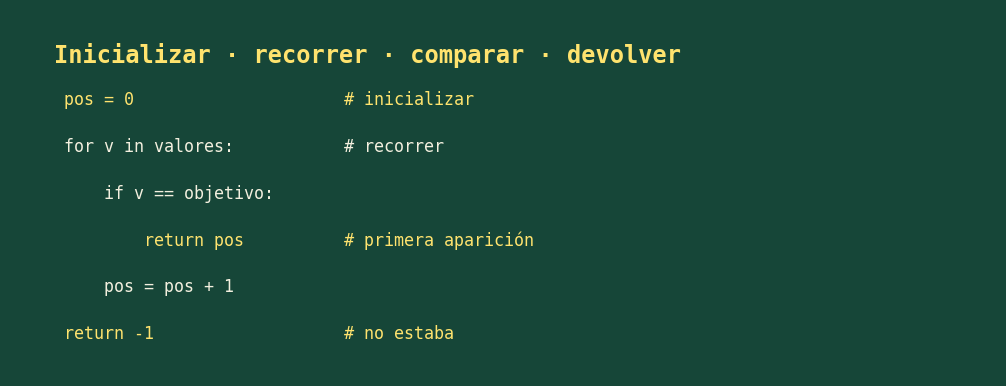

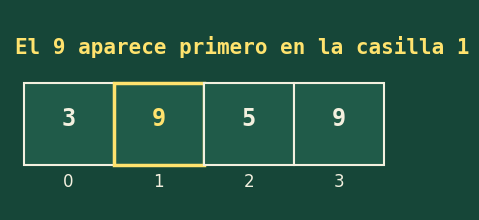

In [20]:
dibujar_pizarra(
    'Inicializar · recorrer · comparar · devolver',
    [('pos = 0                     # inicializar', TIZA_AMARILLA),
    ('for v in valores:           # recorrer', TIZA),
    ('    if v == objetivo:', TIZA),
    ('        return pos          # primera aparición', TIZA_AMARILLA),
    ('    pos = pos + 1', TIZA),
    ('return -1                   # no estaba', TIZA_AMARILLA)],
    ancho=10, alto=3.8,
)
dibujar_lista([3, 9, 5, 9], marcar=[1], titulo="El 9 aparece primero en la casilla 1")

In [21]:
def buscar_posicion(valores, objetivo):
    pos = 0             # posición actual dentro de la lista
    for v in valores:
        if v == objetivo:
            return pos     # encontrado: devolvemos su índice
        pos = pos + 1
    return -1             # recorrimos todo sin encontrarlo

print(buscar_posicion([3, 9, 5, 9], 9))
print(buscar_posicion([3, 9, 5], 7))

1
-1


In [22]:
ejemplos = [
    ('buscar_posicion([3, 9, 5, 9], 9)', '1'),
    ('buscar_posicion([3, 9, 5], 7)', '-1'),
    ('buscar_posicion([], 4)', '-1'),
    ('buscar_posicion([9], 9)', '0'),
]
buscar_posicion.__doc__ = "".join(
    ">>> " + llamada + "\n" + esperado + "\n"
    for llamada, esperado in ejemplos
)
pruebas = doctest.DocTestFinder().find(buscar_posicion, "buscar_posicion")
runner = doctest.DocTestRunner(verbose=True)
for prueba in pruebas:
    runner.run(prueba)
resumen = runner.summarize()
assert resumen.failed == 0
assert resumen.attempted == len(ejemplos)
print(f"Verificado buscar_posicion: {resumen.attempted} pruebas, 0 fallos")

Trying:
    buscar_posicion([3, 9, 5, 9], 9)
Expecting:
    1
ok
Trying:
    buscar_posicion([3, 9, 5], 7)
Expecting:
    -1
ok
Trying:
    buscar_posicion([], 4)
Expecting:
    -1
ok
Trying:
    buscar_posicion([9], 9)
Expecting:
    0
ok
1 items passed all tests:
   4 tests in buscar_posicion
4 tests in 1 items.
4 passed and 0 failed.
Test passed.
Verificado buscar_posicion: 4 pruebas, 0 fallos


**Paso a paso.** `pos` guarda la posición que se está mirando. El `for` recorre la lista; en cuanto un valor coincide con el objetivo se devuelve `pos`, que es la primera aparición. Si el recorrido termina sin encontrarlo, se devuelve -1.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20buscar_posicion%28valores%2C%20objetivo%29%3A%0A%20%20%20%20pos%20%3D%200%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20posici%C3%B3n%20actual%20dentro%20de%20la%20lista%0A%20%20%20%20for%20v%20in%20valores%3A%0A%20%20%20%20%20%20%20%20if%20v%20%3D%3D%20objetivo%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20return%20pos%20%20%20%20%20%23%20encontrado%3A%20devolvemos%20su%20%C3%ADndice%0A%20%20%20%20%20%20%20%20pos%20%3D%20pos%20%2B%201%0A%20%20%20%20return%20-1%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20recorrimos%20todo%20sin%20encontrarlo%0Aprint%28buscar_posicion%28%5B3%2C%209%2C%205%2C%209%5D%2C%209%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Firma según contrato | 0,5 |
| Recorrido de la lista con índice propio | 1,0 |
| Comparación y return de la posición en la primera aparición | 1,0 |
| return -1 tras el bucle | 1,0 |
| devuelve valor, no imprime | 0,5 |

Se aceptan algoritmos equivalentes que cumplan el contrato con lo visto en clase.

#### Errores frecuentes

- Devolver el valor encontrado en lugar de su posición.
- Poner un `return` en la primera vuelta: la función cortaría el recorrido antes de tiempo.
- Contar desde 1: la primera posición es la 0.
- Usar `print` en lugar de `return`: el enunciado pide devolver.

## C2 · Palabras largas de un comentario (4 puntos)

### Enunciado exacto

Los asistentes dejan comentarios escritos en el libro del festival. La organización quiere contar cuántas palabras largas tiene un comentario, entendiendo por larga una palabra con una longitud estrictamente mayor que minimo.

Escribe la función contar_largas(texto, minimo) que reciba una cadena (puede tener espacios extra al principio y al final) y un entero minimo, y devuelva cuántas palabras tienen una longitud estrictamente mayor que minimo.

Ejemplos:

```text
- contar_largas("buenos dias lectores", 5) → 2
- contar_largas("", 3) → 0
```

### Pizarra

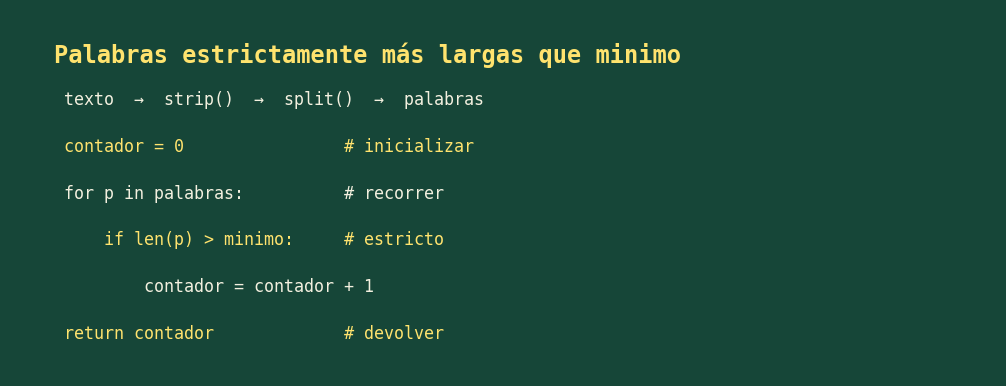

In [23]:
dibujar_pizarra(
    'Palabras estrictamente más largas que minimo',
    [('texto  →  strip()  →  split()  →  palabras', TIZA),
    ('contador = 0                # inicializar', TIZA_AMARILLA),
    ('for p in palabras:          # recorrer', TIZA),
    ('    if len(p) > minimo:     # estricto', TIZA_AMARILLA),
    ('        contador = contador + 1', TIZA),
    ('return contador             # devolver', TIZA_AMARILLA)],
    ancho=10, alto=3.8,
)

In [24]:
def contar_largas(texto, minimo):
    limpio = texto.strip()     # quitamos espacios de los extremos
    palabras = limpio.split()  # lista de palabras; cadena vacía -> lista vacía
    contador = 0
    for p in palabras:
        if len(p) > minimo:
            contador = contador + 1
    return contador

print(contar_largas("buenos dias lectores", 5))
print(contar_largas("", 3))

2
0


In [25]:
ejemplos = [
    ('contar_largas("buenos dias lectores", 5)', '2'),
    ('contar_largas("", 3)', '0'),
    ('contar_largas(" uno dos ", 2)', '2'),
    ('contar_largas("abc", 3)', '0'),
    ('contar_largas("palabra", 0)', '1'),
]
contar_largas.__doc__ = "".join(
    ">>> " + llamada + "\n" + esperado + "\n"
    for llamada, esperado in ejemplos
)
pruebas = doctest.DocTestFinder().find(contar_largas, "contar_largas")
runner = doctest.DocTestRunner(verbose=True)
for prueba in pruebas:
    runner.run(prueba)
resumen = runner.summarize()
assert resumen.failed == 0
assert resumen.attempted == len(ejemplos)
print(f"Verificado contar_largas: {resumen.attempted} pruebas, 0 fallos")

Trying:
    contar_largas("buenos dias lectores", 5)
Expecting:
    2
ok
Trying:
    contar_largas("", 3)
Expecting:
    0
ok
Trying:
    contar_largas(" uno dos ", 2)
Expecting:
    2
ok
Trying:
    contar_largas("abc", 3)
Expecting:
    0
ok
Trying:
    contar_largas("palabra", 0)
Expecting:
    1
ok
1 items passed all tests:
   5 tests in contar_largas
5 tests in 1 items.
5 passed and 0 failed.
Test passed.
Verificado contar_largas: 5 pruebas, 0 fallos


**Paso a paso.** `strip()` quita los espacios de los extremos y `split()` parte el texto en palabras. El contador solo sube cuando `len(p) > minimo`, estricto: una palabra de exactamente `minimo` letras no cuenta. Se devuelve el total.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20contar_largas%28texto%2C%20minimo%29%3A%0A%20%20%20%20limpio%20%3D%20texto.strip%28%29%20%20%20%20%20%23%20quitamos%20espacios%20de%20los%20extremos%0A%20%20%20%20palabras%20%3D%20limpio.split%28%29%20%20%23%20lista%20de%20palabras%3B%20cadena%20vac%C3%ADa%20-%3E%20lista%20vac%C3%ADa%0A%20%20%20%20contador%20%3D%200%0A%20%20%20%20for%20p%20in%20palabras%3A%0A%20%20%20%20%20%20%20%20if%20len%28p%29%20%3E%20minimo%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20contador%20%3D%20contador%20%2B%201%0A%20%20%20%20return%20contador%0Aprint%28contar_largas%28%22buenos%20dias%20lectores%22%2C%205%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Firma según contrato | 0,5 |
| strip + split correctos | 1,0 |
| condicional len(p) > minimo estricto | 1,0 |
| contador y return correctos | 1,0 |
| devuelve valor | 0,5 |

Se aceptan algoritmos equivalentes que cumplan el contrato con lo visto en clase.

#### Errores frecuentes

- Usar `>=` en vez de `>`: una palabra de exactamente `minimo` letras no es larga.
- Recorrer el texto carácter a carácter en vez de hacer `split()`.
- Olvidar el `strip()`: aunque `split()` ya tolera los espacios, la rúbrica lo puntúa junto al `split`.
- Usar `print` en lugar de `return`.

## C3 · Mensaje cifrado del cartel (4 puntos)

### Enunciado exacto

El cartel del festival se anuncia con los nombres cifrados para no desvelar las bandas antes de tiempo. La organización tiene la tabla de sustitución: cada letra tiene su equivalente y los caracteres que no están en la tabla se quedan igual.

Escribe la función codificar(texto, tabla) que reciba una cadena y un diccionario tabla, y devuelva una cadena nueva con cada carácter sustituido por su equivalente en tabla (si no está, se mantiene), usando un solo bucle. No modifiques la tabla ni uses la función print.

Ejemplos:

```text
- codificar("ana", {"a": "@", "n": "#"}) → "@#@"
- codificar("b", {}) → "b"
- codificar("", {}) → ""
```

### Pizarra

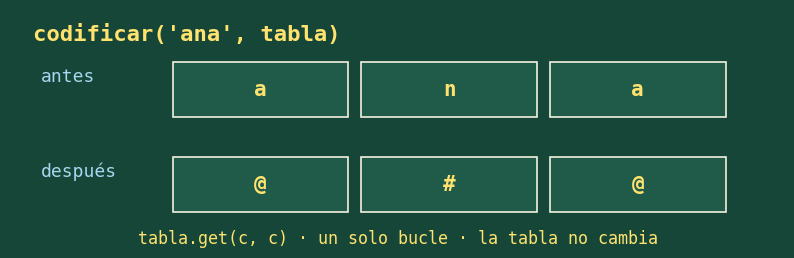

In [26]:
dibujar_listas_doble(list("ana"), list("@#@"), "codificar('ana', tabla)", nota="tabla.get(c, c) · un solo bucle · la tabla no cambia")

In [27]:
def codificar(texto, tabla):
    resultado = ""
    for c in texto:
        resultado = resultado + tabla.get(c, c)
    return resultado

print(codificar("ana", {"a": "@", "n": "#"}))
print(codificar("b", {}))
print(codificar("", {}))

@#@
b



In [28]:
ejemplos = [
    ('codificar("ana", {"a": "@", "n": "#"})', "'@#@'"),
    ('codificar("b", {})', "'b'"),
    ('codificar("", {})', "''"),
    ('codificar("maria", {"m": "M", "a": "A", "r": "R"})', "'MARiA'"),
    ('codificar("Ana", {})', "'Ana'"),
]
codificar.__doc__ = "".join(
    ">>> " + llamada + "\n" + esperado + "\n"
    for llamada, esperado in ejemplos
)
pruebas = doctest.DocTestFinder().find(codificar, "codificar")
runner = doctest.DocTestRunner(verbose=True)
for prueba in pruebas:
    runner.run(prueba)
resumen = runner.summarize()
assert resumen.failed == 0
assert resumen.attempted == len(ejemplos)
tabla = {"a": "@", "n": "#"}
copia = dict(tabla)
assert codificar("ana", tabla) == "@#@"
assert tabla == copia
print("la tabla no se ha modificado")
print(f"Verificado codificar: {resumen.attempted} pruebas, 0 fallos")

Trying:
    codificar("ana", {"a": "@", "n": "#"})
Expecting:
    '@#@'
ok
Trying:
    codificar("b", {})
Expecting:
    'b'
ok
Trying:
    codificar("", {})
Expecting:
    ''
ok
Trying:
    codificar("maria", {"m": "M", "a": "A", "r": "R"})
Expecting:
    'MARiA'
ok
Trying:
    codificar("Ana", {})
Expecting:
    'Ana'
ok
1 items passed all tests:
   5 tests in codificar
5 tests in 1 items.
5 passed and 0 failed.
Test passed.
la tabla no se ha modificado
Verificado codificar: 5 pruebas, 0 fallos


**Paso a paso.** `resultado` nace vacía y el `for` recorre el texto carácter a carácter. `tabla.get(c, c)` da el equivalente si la letra está en la tabla y la propia letra si no. La tabla no se toca y la cadena nueva se devuelve al final.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20codificar%28texto%2C%20tabla%29%3A%0A%20%20%20%20resultado%20%3D%20%22%22%0A%20%20%20%20for%20c%20in%20texto%3A%0A%20%20%20%20%20%20%20%20resultado%20%3D%20resultado%20%2B%20tabla.get%28c%2C%20c%29%0A%20%20%20%20return%20resultado%0Aprint%28codificar%28%22ana%22%2C%20%7B%22a%22%3A%20%22%40%22%2C%20%22n%22%3A%20%22%23%22%7D%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Firma según contrato | 0,5 |
| bucle único sobre el texto | 1,0 |
| sustitución con tabla.get(c, c) o equivalente | 1,5 |
| acumulación de la cadena resultado y return correcto | 1,0 |

Se aceptan algoritmos equivalentes que cumplan el contrato con lo visto en clase.

#### Errores frecuentes

- Modificar la tabla dentro del bucle: el enunciado lo prohíbe y la comprobación lo detecta.
- Usar `tabla[c]` en vez de `tabla.get(c, c)`: falla cuando el carácter no está en la tabla.
- Meter un segundo bucle: el enunciado pide uno solo.
- Usar `print` en lugar de `return`.

# Resumen final

| Ejercicio | Respuesta oficial | Puntos |
|---|---|---:|
| A1-A3 | a) 6 · c) 0 3 · b) 20 | 2 c/u |
| B1 | tabla de 3 filas; `revistas: 12`, `paquetes: 3` | 3 |
| B2 | tabla de 4 filas; `posicion: 3` | 3 |
| B3 | tabla de 5 filas; `['4', '7']`, `letras: 3` | 3 |
| B4 | tabla de 5 filas; `total: 6`, `desconocidos: 1` | 3 |
| C1 | `buscar_posicion`: 1, -1, -1, 0 | 4 |
| C2 | `contar_largas`: 2, 0, 2, 0, 1 | 4 |
| C3 | `codificar`: "@#@", "b", "", "MARiA", "Ana" | 4 |
| **Total** | **A: 6 · B: 12 · C: 12** | **30** |

## Dudas frecuentes

**¿Por qué A1 imprime 6 y no 5?**  
El bucle interior da 3 vueltas por cada una de las 2 del exterior: se multiplican (2 × 3 = 6), no se suman.

**¿Por qué `encontrado` empieza en -1 en B2?**  
Es el centinela de «aún no se ha encontrado nada»; si ningún retraso supera los 10 minutos, la respuesta queda en -1.

**¿Cuenta la vuelta en la que salta el `break`?**  
Sí: la rúbrica pide los valores al final de cada vuelta, incluida la vuelta del break.

**¿Tiene que ser exacta la salida?**  
Sí: en cada ejercicio de la parte B, 0,5 puntos corresponden al orden y al formato exactos (corchetes, comillas, orden de las líneas).

**¿Puedo usar `while` en C1?**  
Sí: se aceptan algoritmos equivalentes que cumplan el contrato con lo visto en clase.

**¿Puedo modificar la tabla en C3?**  
No: hay que devolver una cadena nueva y dejar la tabla intacta.